# Customer Churn Prediction

**Goal:** predict which telecom customers are likely to leave (churn) so the business can act before they go.
**Problem type:** binary classification (`Churn` = 1 leaves, 0 stays).
**Models:** Logistic Regression (baseline), Random Forest, XGBoost.

## process
1. Explore data (EDA) and find churn drivers
2. Clean data and engineer features
3. Split data and avoid **data leakage** with Pipelines
4. Train and compare three models with cross-validation
5. Evaluate with the right metrics (not accuracy)
6. Tune hyperparameters and the decision threshold using business cost
7. Explain the model and save it

## Step 0: Setup
Import the libraries. XGBoost is optional here: if it isn't installed, the notebook falls back to scikit-learn's
`HistGradientBoostingClassifier` (a similar boosting model) so everything still runs.
Install everything with `pip install -r requirements.txt`.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report)
from sklearn.inspection import permutation_importance

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not installed -> using HistGradientBoostingClassifier as the third model.")

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Setup done. XGBoost available:", HAS_XGB)

Setup done. XGBoost available: True


## Step 1: Load the data

In [3]:
DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 2: Explore the data (EDA)
Before modelling, understand the data. Key questions:
- How many customers churn? (class imbalance)
- Which features seem related to churn?

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.shape

(7043, 21)

Churn rate: 26.5%  (so the data is imbalanced)


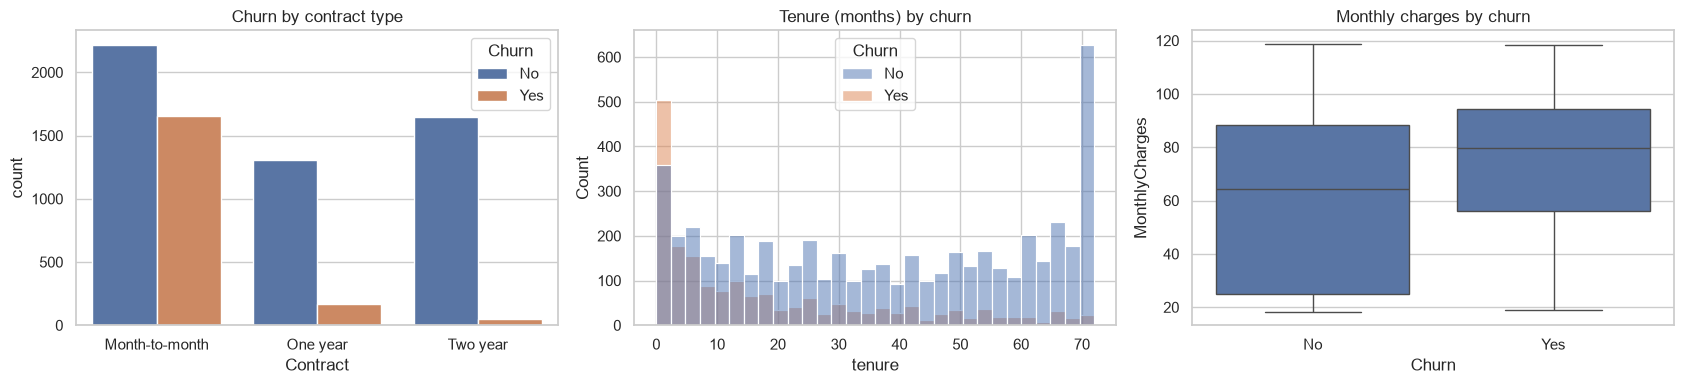

In [7]:
churn_rate = (df["Churn"] == "Yes").mean()
print(f"Churn rate: {churn_rate:.1%}  (so the data is imbalanced)")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0])
axes[0].set_title("Churn by contract type")
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[1])
axes[1].set_title("Tenure (months) by churn")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[2])
axes[2].set_title("Monthly charges by churn")
plt.tight_layout()
plt.show()

In [8]:
# Churn rate inside each category: a quick way to spot strong drivers
for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "PaperlessBilling"]:
    rates = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
    print(f"\n{col}\n{rates.round(3).to_string()}")


Contract
Contract
Month-to-month    0.427
One year          0.113
Two year          0.028

InternetService
InternetService
Fiber optic    0.419
DSL            0.190
No             0.074

PaymentMethod
PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152

TechSupport
TechSupport
No                     0.416
Yes                    0.152
No internet service    0.074

PaperlessBilling
PaperlessBilling
Yes    0.336
No     0.163


**What to look for:** customers on month-to-month contracts, with short tenure, higher bills, fibre internet and no tech support
usually churn the most. Write down your own observations. The model should later confirm them.

## Step 3: Clean the data
Common issues in this dataset:
- `customerID` is just an identifier, so it is useless for prediction.
- `TotalCharges` is stored as text and has blank values (these are brand-new customers with `tenure = 0`, so 0 is a sensible fill).
- The target `Churn` is "Yes"/"No", so we convert it to 1/0.

In [9]:
df = df.drop(columns=["customerID"])

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("Duplicate rows:", df.duplicated().sum())
print("Missing values left:", df.isna().sum().sum())

Blank TotalCharges: 11
Duplicate rows: 22
Missing values left: 0


## Step 4: Feature engineering
Creating new features from existing ones often helps more than switching models. These are row-by-row calculations
(they don't use other rows' statistics), so doing them before the split causes no leakage.

In [10]:
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

# How many services does the customer use? (more services -> more "sticky")
df["num_services"] = (df[service_cols] == "Yes").sum(axis=1) + (df["InternetService"] != "No").astype(int)

# Average amount actually paid per month over the customer's life
df["avg_monthly_spend"] = (df["TotalCharges"] / df["tenure"].replace(0, np.nan)).fillna(df["MonthlyCharges"])

# Has protection / support services?
df["has_support"] = ((df["OnlineSecurity"] == "Yes") | (df["TechSupport"] == "Yes")).astype(int)

# Tenure bucket
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, np.inf],
                            labels=["0-12", "13-24", "25-48", "49+"]).astype(str)

df[["tenure", "tenure_group", "num_services", "avg_monthly_spend", "has_support"]].head()

,tenure,tenure_group,num_services,avg_monthly_spend,has_support
0,1,0-12,2,29.850000,0
1,34,25-48,4,55.573529,1
2,2,0-12,4,54.075000,1
3,45,25-48,4,40.905556,1
4,2,0-12,2,75.825000,0


## Step 5: Train/test split
`stratify=y` keeps the same churn ratio in both sets. The test set is locked away until the end and only used for the final score.

In [11]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Train: (5634, 23)  Test: (1409, 23)
Churn rate train/test: 0.265 0.265


## Step 6: Preprocessing pipeline
- Numeric columns are scaled (needed for logistic regression, harmless for trees).
- Categorical columns are one-hot encoded.

We wrap preprocessing and model together in a **Pipeline**. During cross-validation the scaler/encoder is re-fitted only on
each training fold, which prevents **data leakage** automatically.

In [12]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_services', 'avg_monthly_spend', 'has_support']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']


## Step 7: Build the three models
| Model | Why it is here |
|---|---|
| **Logistic Regression** | Simple, fast, interpretable. This is your **baseline**. |
| **Random Forest** | Many decision trees voting. Captures non-linear patterns and interactions. |
| **XGBoost** | Boosted trees. Usually the strongest on tabular data. |

Class imbalance is handled inside each model (`class_weight` / `scale_pos_weight`) so that churners are not ignored.

In [13]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos   # tells XGBoost how much rarer churners are

def make_boosting_model():
    if HAS_XGB:
        return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8,
                             scale_pos_weight=scale_pos_weight,
                             eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)
    return HistGradientBoostingClassifier(max_iter=300, max_depth=4, learning_rate=0.05,
                                          class_weight="balanced", random_state=RANDOM_STATE)

BOOST_NAME = "XGBoost" if HAS_XGB else "HistGradientBoosting"

models = {
    "Logistic Regression": Pipeline([
        ("prep", make_preprocessor()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]),
    "Random Forest": Pipeline([
        ("prep", make_preprocessor()),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                         class_weight="balanced_subsample",
                                         random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    BOOST_NAME: Pipeline([
        ("prep", make_preprocessor()),
        ("model", make_boosting_model()),
    ]),
}
list(models)

['Logistic Regression', 'Random Forest', 'XGBoost']

## Step 8: Cross-validation (fair comparison on training data)
5-fold stratified cross-validation gives a more reliable estimate than one split. We use **ROC-AUC** (ranking quality)
and **recall** (how many real churners we catch).

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, pipe in models.items():
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    rec = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="recall")
    cv_rows.append({"Model": name,
                    "CV ROC-AUC": f"{auc.mean():.3f} ± {auc.std():.3f}",
                    "CV Recall": f"{rec.mean():.3f} ± {rec.std():.3f}"})
pd.DataFrame(cv_rows)

,Model,CV ROC-AUC,CV Recall
0,Logistic Regression,0.846 ± 0.012,0.794 ± 0.042
1,Random Forest,0.845 ± 0.009,0.714 ± 0.041
2,XGBoost,0.845 ± 0.011,0.779 ± 0.027


## Step 9: Train on the full training set and evaluate on the test set
**Never judge by accuracy alone.** If 73% of customers stay, a model that says "nobody churns" gets 73% accuracy and is useless.
- **Recall:** of customers who really churned, how many did we catch?
- **Precision:** of customers we flagged, how many really churned?
- **F1:** balance of the two. **ROC-AUC:** overall ranking quality.

In [15]:
def evaluate(name, model, X_te, y_te, threshold=0.5):
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"Model": name,
            "Accuracy": accuracy_score(y_te, pred),
            "Precision": precision_score(y_te, pred),
            "Recall": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred),
            "ROC-AUC": roc_auc_score(y_te, proba)}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)

results = pd.DataFrame([evaluate(n, m, X_test, y_test) for n, m in models.items()]).set_index("Model")
results.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.737,0.503,0.786,0.613,0.842
Random Forest,0.767,0.547,0.719,0.621,0.840
XGBoost,0.754,0.525,0.773,0.626,0.842


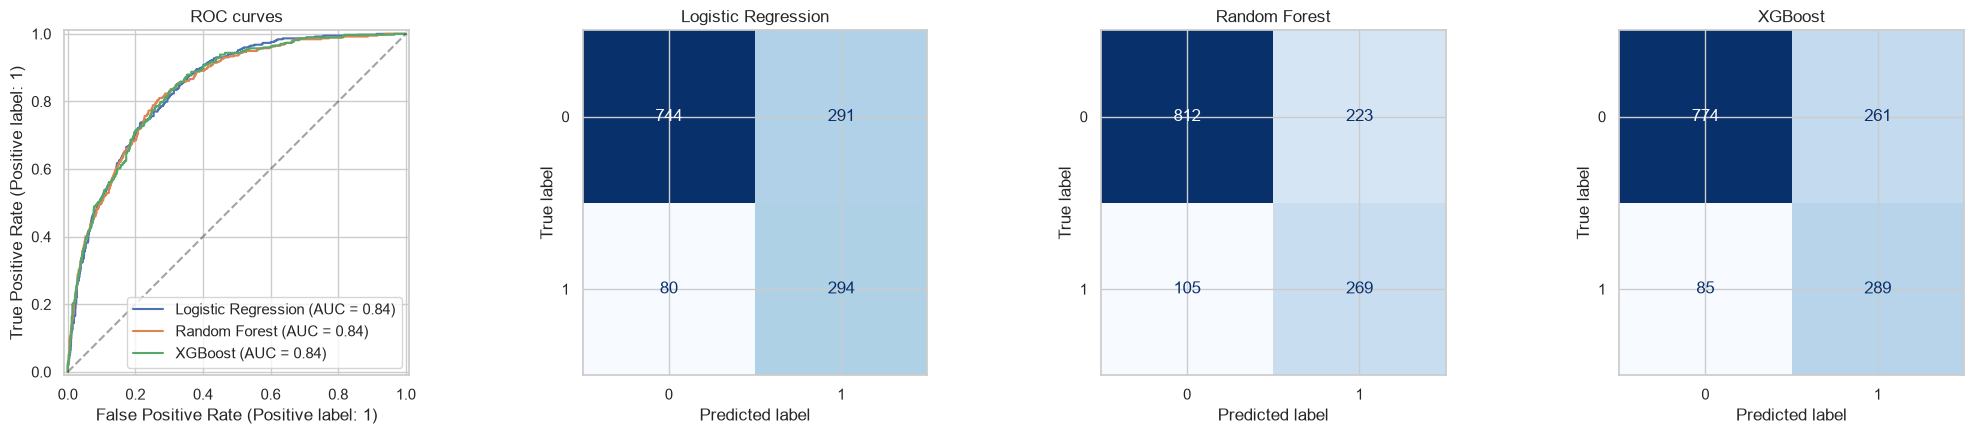

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))

# ROC curves
for name, pipe in models.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC curves")

# Confusion matrices
for ax, (name, pipe) in zip(axes[1:], models.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**How to read the confusion matrix:** the bottom-left cell (actual churn, predicted stay) is the **false negatives**,
which are churners we missed. This is usually the costliest mistake.

## Step 10: Hyperparameter tuning
Tune the boosting model with `RandomizedSearchCV` (tries random combinations; faster than a full grid).
You can swap in any of the three models here.

In [17]:
if HAS_XGB:
    param_dist = {
        "model__n_estimators": [100, 200, 300, 500],
        "model__max_depth": [3, 4, 5, 6],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__subsample": [0.7, 0.8, 1.0],
        "model__colsample_bytree": [0.6, 0.8, 1.0],
        "model__min_child_weight": [1, 3, 5],
    }
else:
    param_dist = {
        "model__max_iter": [100, 200, 300, 500],
        "model__max_depth": [3, 4, 5, 6],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__min_samples_leaf": [10, 20, 40],
    }

search = RandomizedSearchCV(models[BOOST_NAME], param_dist, n_iter=15, cv=3,
                            scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(search.best_score_, 3))
print("Best params:", search.best_params_)
best_model = search.best_estimator_
print("Tuned test result:")
pd.DataFrame([evaluate(f"Tuned {BOOST_NAME}", best_model, X_test, y_test)]).set_index("Model").round(3)

Best CV ROC-AUC: 0.85
Best params: {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__min_child_weight': 3, 'model__max_depth': 5, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.6}
Tuned test result:


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Tuned XGBoost,0.76,0.532,0.805,0.64,0.846


## Step 11: Choose the decision threshold using business cost
A model outputs a probability. The default cut-off of 0.5 isn't always best.
Suppose (change these to match your business):
- Losing a customer who we failed to flag costs **₹500** (false negative)
- Offering a retention discount to someone who wasn't leaving costs **₹50** (false positive)

We pick the threshold using **out-of-fold predictions on the training set** (not the test set), so the test set stays an honest final exam.

Best threshold by business cost: 0.19


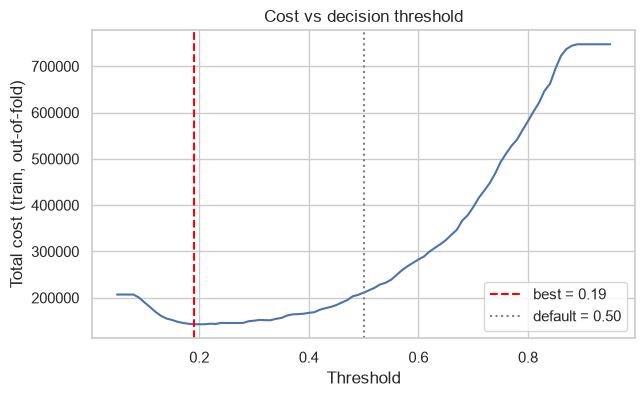

In [18]:
COST_FN = 500   # missed churner
COST_FP = 50    # unnecessary retention offer

oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)
costs = []
for t in thresholds:
    pred = (oof_proba >= t).astype(int)
    fn = ((pred == 0) & (y_train == 1)).sum()
    fp = ((pred == 1) & (y_train == 0)).sum()
    costs.append(fn * COST_FN + fp * COST_FP)

best_threshold = float(thresholds[int(np.argmin(costs))])
print(f"Best threshold by business cost: {best_threshold:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, costs)
plt.axvline(best_threshold, color="red", ls="--", label=f"best = {best_threshold:.2f}")
plt.axvline(0.5, color="gray", ls=":", label="default = 0.50")
plt.xlabel("Threshold"); plt.ylabel("Total cost (train, out-of-fold)")
plt.title("Cost vs decision threshold"); plt.legend(); plt.show()

In [19]:
# Final exam on the untouched test set: default threshold vs cost-optimised threshold
final = pd.DataFrame([
    evaluate("Tuned model @ 0.50", best_model, X_test, y_test, threshold=0.5),
    evaluate(f"Tuned model @ {best_threshold:.2f}", best_model, X_test, y_test, threshold=best_threshold),
]).set_index("Model")
display(final.round(3))

pred_final = (best_model.predict_proba(X_test)[:, 1] >= best_threshold).astype(int)
print(classification_report(y_test, pred_final, target_names=["Stay", "Churn"]))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Tuned model @ 0.50,0.760,0.532,0.805,0.640,0.846
Tuned model @ 0.19,0.529,0.358,0.979,0.524,0.846


              precision    recall  f1-score   support

        Stay       0.98      0.37      0.53      1035
       Churn       0.36      0.98      0.52       374

    accuracy                           0.53      1409
   macro avg       0.67      0.67      0.53      1409
weighted avg       0.81      0.53      0.53      1409



## Step 12: Explain the model (why do customers churn?)
Businesses need reasons, not just scores.
1. **Logistic Regression coefficients:** positive = pushes toward churn, negative = toward staying.
2. **Permutation importance:** how much the score drops when a feature is shuffled (works for any model).
3. **SHAP (optional):** per-customer explanations if the `shap` library is installed.

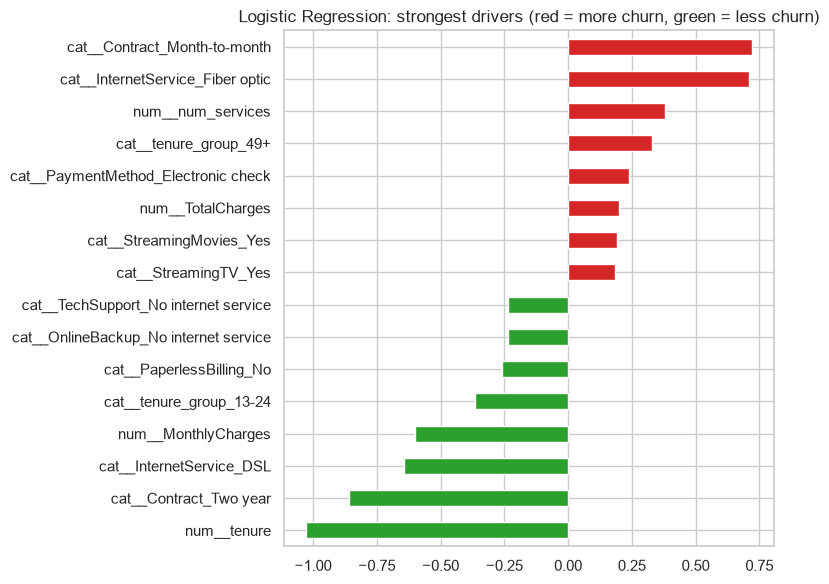

In [20]:
# 1) Logistic regression coefficients
lr_pipe = models["Logistic Regression"]
feat_names = lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=feat_names).sort_values()

top = pd.concat([coefs.head(8), coefs.tail(8)])
plt.figure(figsize=(8, 6))
top.plot(kind="barh", color=["tab:green" if v < 0 else "tab:red" for v in top])
plt.title("Logistic Regression: strongest drivers (red = more churn, green = less churn)")
plt.tight_layout(); plt.show()

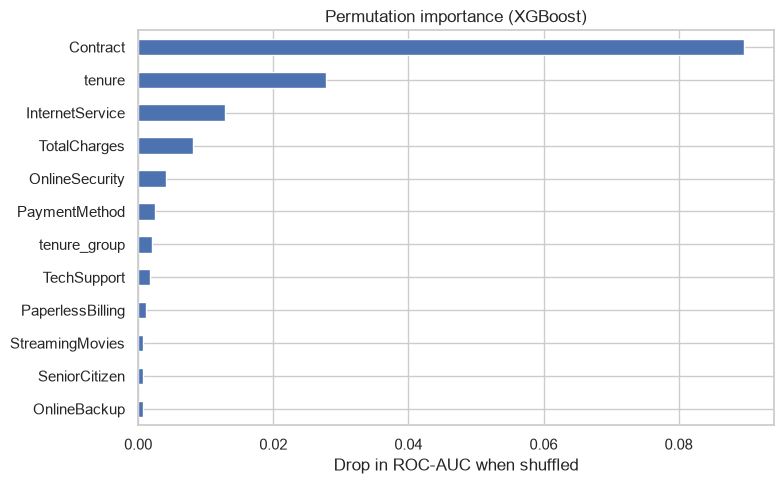

In [21]:
# 2) Permutation importance on the tuned model (uses original column names)
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False).head(12)

plt.figure(figsize=(8, 5))
perm_imp[::-1].plot(kind="barh")
plt.title(f"Permutation importance ({BOOST_NAME})")
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.tight_layout(); plt.show()

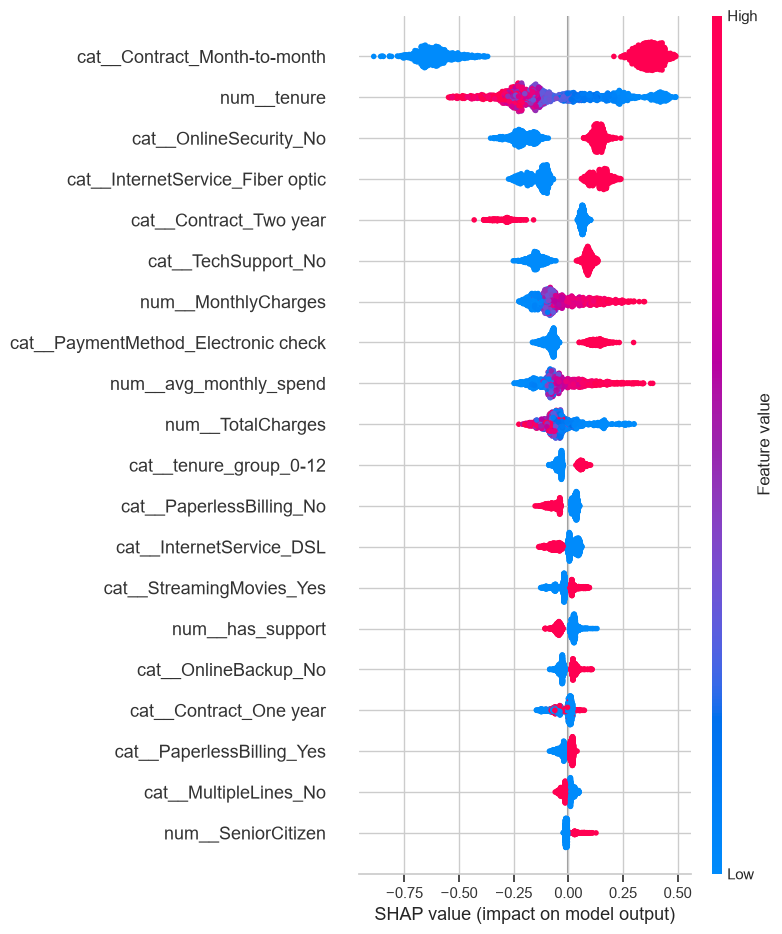

In [22]:
# 3) SHAP (optional): skipped automatically if shap isn't installed
try:
    import shap
    prep = best_model.named_steps["prep"]
    X_test_t = prep.transform(X_test)
    if hasattr(X_test_t, "toarray"):
        X_test_t = X_test_t.toarray()
    names = prep.get_feature_names_out()
    explainer = shap.TreeExplainer(best_model.named_steps["model"])
    shap_values = explainer.shap_values(X_test_t)
    shap.summary_plot(shap_values, X_test_t, feature_names=names, show=True)
except Exception as e:
    print("SHAP skipped:", type(e).__name__, "-", e)

## Step 13: Save the model and make a prediction
We save the pipeline (preprocessing + model) together with the threshold, so new raw customer data can be scored directly.

In [24]:
joblib.dump({"model": best_model, "threshold": best_threshold,
             "feature_columns": X_train.columns.tolist()}, "churn_model.joblib")

# Load it back and score a customer
bundle = joblib.load("churn_model.joblib")
customer = X_test.iloc[[0]]
prob = bundle["model"].predict_proba(customer)[0, 1]
print(f"Churn probability: {prob:.1%}")
print("Decision:", "HIGH RISK -> send retention offer" if prob >= bundle["threshold"] else "Low risk")

Churn probability: 10.9%
Decision: Low risk
